# SEIS 763 - Final Project
## Maeva Lago - Karen Navarro - Laurel Thompson

In [1]:
## imports
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
import statsmodels.api as sm
import matplotlib.pyplot as plt
import numpy as np

from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

In [2]:
#Global variables
random_state = 17

## Step 1: Data Preprocessing

In this step, we prepare the dataset for machine learning by selecting features relevant to our hypothesis, splitting the data into training and testing sets, checking for missing values, encoding categorical variables, standardizing features, and balancing the training data using SMOTE.

1. **Load the dataset and select features**
   - Load the dataset and display the first five rows.
   - Remove the `user_id` column.
   - Select behavioral and environmental features relevant to our hypothesis, along with chronotype.
   - Define the independent variables (X) and target variable (y), `sleep_debt_category`.

2. **Split the dataset**
   - Split the dataset into 80% training and 20% testing.
   - Use stratification to preserve the target class distribution.

3. **Check for missing values**
   - Check the training and testing datasets for missing values.
   - Since no missing values were found, no imputation is required.

4. **Encode categorical variables**
   - Apply one-hot encoding to `chronotype`, `primary_app_category`, and `blue_light_filter_on`.
   - Ensure the training and testing datasets have matching columns.
   - Encode the target labels for classification.

5. **Standardize features**
   - Use `StandardScaler` to standardize the input features.
   - Fit the scaler on the training data and transform the testing data using the same scaler.

6. **Balance the training data using SMOTE**
   - Apply SMOTE to address class imbalance in the training dataset.
   - Keep the testing dataset unchanged for unbiased model evaluation.

Feature selection is based on our research hypothesis rather than backward elimination. This allows us to evaluate whether behavioral and environmental factors can predict sleep debt categories.

### Some fixes 
- Combine Moderate and Severe into Moderate-Severe, since Severe is only 0.29% of the data. This is done before the split so stratification uses the final classes.  
- Shift bedtime_hour to hours since 6 PM so that times across midnight are continuous  
- fix random state in smote so it follows the global environment set in first cell  
- standardize the input features to standardize the numeric features (dummy columns are left as 0/1)
- add missing features like age, gender, occupation  from the features list 
- add gender and occupation to one hot encoding  
- add age to numeric features to standardize  

In [3]:
#Load our data
data = pd.read_csv('/Users/navar135/Documents/UST/SEIS 763 Machine Learning/Final Project/insomnia_dataset/sleep_debt_screen_time.csv')
display(data.head())

,user_id,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,...,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score,sleep_debt_category
0,1,32,Female,Intermediate,Student,23.94,102,Social Media,100,False,...,73.5,32.6,60.3,5.67,15.2,13.5,11,63.7,8.85,Moderate
1,2,26,Female,Intermediate,Student,0.06,14,Short-Form Video,87,True,...,66.8,44.3,24.5,7.42,16.9,22.3,1,92.9,2.98,No Debt
2,3,34,Male,Night Owl,Professional,1.48,58,Messaging,76,True,...,68.0,45.6,21.9,6.98,20.2,18.5,2,84.6,3.90,Mild
3,4,43,Female,Intermediate,Professional,22.42,48,Social Media,56,False,...,72.3,42.3,34.5,7.67,14.4,17.3,6,79.9,4.81,No Debt
4,5,25,Male,Early Bird,Professional,22.43,29,Streaming,96,True,...,80.1,10.0,37.4,6.31,16.6,16.1,0,89.3,3.88,Mild


## Justification for excluding sleep-outcome variables

The following columns are sleep-outcome measurements recorded *after* the night of sleep: `sleep_onset_latency_min`, `total_sleep_hours`, `rem_sleep_pct`, `deep_sleep_pct`, `awakenings_count`, and `sleep_efficiency_pct`. We also exclude `next_day_fatigue_score`, which is a consequence of the same sleep outcomes. Our goal is to predict sleep debt from modifiable behaviors and the sleep environment (bedtime, screen use, caffeine, noise, temperature), so using measurements of the sleep itself would amount to predicting the answer from the answer.

The data-generation script (`generate_dataset.py`) shows that the target is a direct function of one of these columns:

    ideal_sleep = 8.5 if age < 25, 7.5 if age < 45, otherwise 7.0  
    sleep_debt_hours = ideal_sleep - total_sleep_hours  
    sleep_debt_category = No Debt (< 0.5 h), Mild (< 1.5 h), Moderate (< 3.0 h), Severe (otherwise)

`total_sleep_hours` is in turn built from sleep onset latency, bedtime, melatonin suppression, and caffeine, so the other outcome columns are downstream of the same causes. The cells below confirm this empirically: (1) the label can be reconstructed exactly from `age` and `total_sleep_hours`, and (2) the outcome columns predict the label far better than the behavioral features do. Because `age` determines the ideal sleep duration, we keep it as a predictor.

In [4]:
# Reconstruct the target from total_sleep_hours and age using the rule from the data generator
ideal_sleep = np.where(data['age'] < 25, 8.5, np.where(data['age'] < 45, 7.5, 7.0))
sleep_debt_hours = ideal_sleep - data['total_sleep_hours']
reconstructed = np.where(sleep_debt_hours < 0.5, 'No Debt',
                np.where(sleep_debt_hours < 1.5, 'Mild',
                np.where(sleep_debt_hours < 3.0, 'Moderate', 'Severe')))

match = (reconstructed == data['sleep_debt_category']).mean()
print(f"Label reproduced from age + total_sleep_hours: {match:.2%} of rows")
display(pd.crosstab(reconstructed, data['sleep_debt_category'],
                    rownames=['reconstructed'], colnames=['actual']))

Label reproduced from age + total_sleep_hours: 100.00% of rows


actual,Mild,Moderate,No Debt,Severe
reconstructed,,,,
Mild,4393,0,0,0
Moderate,0,2361,0,0
No Debt,0,0,1721,0
Severe,0,0,0,25


## Fix Bedtime Scale 

In [5]:
display(data['bedtime_hour'].describe())
# Make bedtime continuous across midnight: hours since 18:00 (6 PM)
# e.g. 22.0 -> 4.0, 0.0 -> 6.0, 2.0 -> 8.0
data['bedtime_hour'] = (data['bedtime_hour'] - 18) % 24
display(data['bedtime_hour'].describe())

count    8500.000000
mean       13.883186
std        10.836579
min         0.000000
25%         1.090000
50%        22.200000
75%        23.150000
max        24.000000
Name: bedtime_hour, dtype: float64

count    8500.000000
mean        5.790951
std         1.206503
min         2.750000
25%         4.860000
50%         5.700000
75%         6.670000
max         9.500000
Name: bedtime_hour, dtype: float64

## Split data

In [6]:
#Split the data into independent and dependent variables X and Y.

features = [
    'age',
    'gender',
    'chronotype',
    'occupation',
    'bedtime_hour',
    'screen_time_before_bed_min',
    'primary_app_category',
    'screen_brightness_pct',
    'blue_light_filter_on',
    'caffeine_intake_mg',
    'caffeine_last_hour',
    'physical_activity_min',
    'room_temperature_f',
    'ambient_noise_db'
]

X = data[features]
y = data['sleep_debt_category']
X.shape, y.shape

((8500, 14), (8500,))

### Combine moderate and severe buckets in sleep debt category

In [7]:
#combine last two categories that have very low count
display(y.value_counts())
y = data['sleep_debt_category'].replace({'Moderate': 'Moderate-Severe', 'Severe': 'Moderate-Severe'})
y.value_counts()

sleep_debt_category
Mild        4393
Moderate    2361
No Debt     1721
Severe        25
Name: count, dtype: int64

sleep_debt_category
Mild               4393
Moderate-Severe    2386
No Debt            1721
Name: count, dtype: int64

In [8]:
X_train, X_test, y_train, y_test= train_test_split(X, y, test_size=0.2, random_state=random_state, stratify=y)

In [9]:
x_training_missing_values = X_train.isnull().sum()
print("Missing values in X_train:")
print(x_training_missing_values)

Missing values in X_train:
age                           0
gender                        0
chronotype                    0
occupation                    0
bedtime_hour                  0
screen_time_before_bed_min    0
primary_app_category          0
screen_brightness_pct         0
blue_light_filter_on          0
caffeine_intake_mg            0
caffeine_last_hour            0
physical_activity_min         0
room_temperature_f            0
ambient_noise_db              0
dtype: int64


In [10]:
x_testing_missing_values = X_test.isnull().sum()
print("Missing values in X_test:")
print(x_testing_missing_values)

Missing values in X_test:
age                           0
gender                        0
chronotype                    0
occupation                    0
bedtime_hour                  0
screen_time_before_bed_min    0
primary_app_category          0
screen_brightness_pct         0
blue_light_filter_on          0
caffeine_intake_mg            0
caffeine_last_hour            0
physical_activity_min         0
room_temperature_f            0
ambient_noise_db              0
dtype: int64


## One hot encode categorical variables

In [11]:
#One hot encode categorical variables
# 0 = Mild, 1 = Moderate-Severe, 2 = No Debt.
X_train_encoded = pd.get_dummies(X_train, columns=['gender','occupation','chronotype', 'primary_app_category', 'blue_light_filter_on'], drop_first=True)
X_test_encoded =  pd.get_dummies(X_test, columns=['gender','occupation','chronotype', 'primary_app_category', 'blue_light_filter_on'], drop_first=True)

# Ensure test data has the same columns as training data
X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)
display(X_train_encoded)

,age,bedtime_hour,screen_time_before_bed_min,screen_brightness_pct,caffeine_intake_mg,caffeine_last_hour,physical_activity_min,room_temperature_f,ambient_noise_db,gender_Male,...,occupation_Unemployed,chronotype_Intermediate,chronotype_Night Owl,primary_app_category_Gaming,primary_app_category_Messaging,primary_app_category_News,primary_app_category_Short-Form Video,primary_app_category_Social Media,primary_app_category_Streaming,blue_light_filter_on_True
6254,24,4.25,58,83,88,13.2,46,66.0,33.7,True,...,False,False,False,False,False,False,False,True,False,False
301,22,5.39,34,64,31,13.0,54,64.7,27.8,False,...,False,False,True,False,False,False,True,False,False,True
2134,24,5.50,139,81,500,11.5,19,63.6,46.5,True,...,False,False,False,False,False,True,False,False,False,True
4184,23,4.25,49,46,108,11.3,32,69.9,33.4,False,...,False,False,False,False,False,False,True,False,False,False
7370,30,7.08,17,66,66,9.4,1,67.2,33.4,True,...,False,False,True,False,False,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2382,31,4.96,46,54,89,20.9,2,64.5,19.5,True,...,False,False,False,False,False,False,True,False,False,False
6706,23,8.01,35,55,22,17.7,180,70.1,33.7,True,...,False,False,True,False,False,True,False,False,False,False
7860,48,5.64,27,81,36,11.9,9,68.1,21.7,False,...,False,True,False,False,False,True,False,False,False,False
1258,20,3.43,37,50,97,22.1,27,67.1,11.4,False,...,False,True,False,False,True,False,False,False,False,False


Training class distribution:
0    3514
1    1909
2    1377
Name: count, dtype: int64
-----------------------


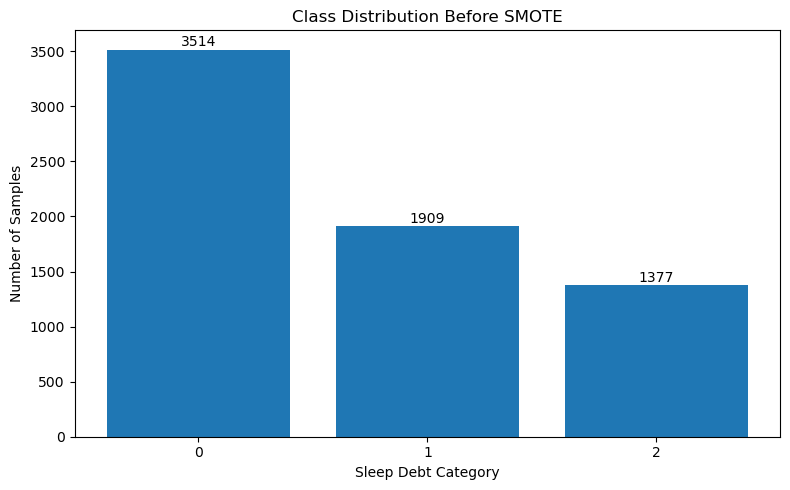

In [12]:
# Label encode the target variable
encoder = LabelEncoder()

y_train = encoder.fit_transform(y_train)
y_test = encoder.transform(y_test)

print("Training class distribution:")
print(pd.Series(y_train).value_counts())

print ("-----------------------")


# Class distribution before SMOTE
class_counts = pd.Series(y_train).value_counts().sort_index()

plt.figure(figsize=(8, 5))
bars = plt.bar(class_counts.index.astype(str), class_counts.values)

# Add count labels above bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 30,
        int(bar.get_height()),
        ha='center'
    )

plt.title("Class Distribution Before SMOTE")
plt.xlabel("Sleep Debt Category")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


The graph shows a significant class imbalance in the training dataset. Class 0 represents approximately 51.68% of the observations, while Class 3 accounts for only 0.29%. This imbalance could cause the classifiers to favor the majority class and perform poorly when predicting minority classes. To address this issue, we will apply SMOTE down the road to the training data and evaluate its impact on model performance.

## Scale numerical columns

In [13]:
numeric_cols = ['age','bedtime_hour', 'screen_time_before_bed_min', 'screen_brightness_pct',
                'caffeine_intake_mg', 'caffeine_last_hour', 'physical_activity_min',
                'room_temperature_f', 'ambient_noise_db']
# Sanity check on numeric columns only (the whole-matrix mean/std you print now is not informative)
print(X_train_encoded[numeric_cols].mean().round(3))
print(X_train_encoded[numeric_cols].std().round(3))
scaler = StandardScaler()
X_train = X_train_encoded.copy()
X_test = X_test_encoded.copy()
X_train[numeric_cols] = scaler.fit_transform(X_train_encoded[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test_encoded[numeric_cols])

# Sanity check on numeric columns only (the whole-matrix mean/std you print now is not informative)
print("\n")
print(X_train[numeric_cols].mean().round(3))
print(X_train[numeric_cols].std().round(3))

age                           28.117
bedtime_hour                   5.796
screen_time_before_bed_min    53.660
screen_brightness_pct         68.724
caffeine_intake_mg            79.811
caffeine_last_hour            15.917
physical_activity_min         29.902
room_temperature_f            70.082
ambient_noise_db              35.011
dtype: float64
age                            8.943
bedtime_hour                   1.210
screen_time_before_bed_min    35.117
screen_brightness_pct         18.899
caffeine_intake_mg            78.754
caffeine_last_hour             3.828
physical_activity_min         29.866
room_temperature_f             3.941
ambient_noise_db              10.012
dtype: float64


age                          -0.0
bedtime_hour                 -0.0
screen_time_before_bed_min    0.0
screen_brightness_pct         0.0
caffeine_intake_mg           -0.0
caffeine_last_hour            0.0
physical_activity_min        -0.0
room_temperature_f           -0.0
ambient_noise_db              

## Feature selection via backward elimination 

In [24]:

# Backward elimination with 5-fold CV on the training data.
# Running it before SMOTE keeps synthetic rows from leaking across CV folds.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)
lr = LogisticRegression(max_iter=1000, class_weight='balanced')

sfs = SequentialFeatureSelector(
    lr,
    n_features_to_select='auto',
    tol=-.001,            # negative for backward: keep removing a feature as long as CV macro-F1 drops by less than 0.002
    direction='backward',
    scoring='f1_macro',    # macro-F1 so the smaller classes count equally
    cv=cv,
    n_jobs=-1
)
sfs.fit(X_train, y_train)

selected = list(X_train.columns[sfs.get_support()])
dropped = list(X_train.columns[~sfs.get_support()])
print(f"Selected ({len(selected)}):", selected)
print(f"Dropped ({len(dropped)}):", dropped)

X_train_sel = X_train[selected]
X_test_sel = X_test[selected]

Selected (16): ['bedtime_hour', 'screen_time_before_bed_min', 'screen_brightness_pct', 'caffeine_intake_mg', 'caffeine_last_hour', 'physical_activity_min', 'room_temperature_f', 'gender_Male', 'occupation_Professional', 'occupation_Retired', 'occupation_Student', 'primary_app_category_Gaming', 'primary_app_category_Short-Form Video', 'primary_app_category_Social Media', 'primary_app_category_Streaming', 'blue_light_filter_on_True']
Dropped (8): ['age', 'ambient_noise_db', 'gender_Non-Binary', 'occupation_Unemployed', 'chronotype_Intermediate', 'chronotype_Night Owl', 'primary_app_category_Messaging', 'primary_app_category_News']


## Resample via SMOTE

In [15]:
# smote = SMOTE(random_state=random_state)

# X_train_smote, y_train_smote = smote.fit_resample(
#     X_train_sel, y_train
# )

# print("\nAfter SMOTE:")
# print(pd.Series(y_train_smote).value_counts())

## Random Forest 

### Note on SMOTE and model training

In the previous step, we used SMOTE to show how the training classes can be balanced. We do not use that balanced data to train or tune therandom forest model, because it would make our results look better than they really are.

SMOTE creates new, made-up rows by copying and blending real ones. If we create these rows first and then test the model on part of the same data, the model is tested on rows that are very similar to ones it has already seen. That makes the scores unfairly high.

To avoid this, SMOTE is built into the model pipeline. Each time the data is split for testing, SMOTE only adds new rows to the training part. The part used for testing contains only real data. The final test set is never changed, so our final results show how the model would do on new data.

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best params: {'rf__n_estimators': 200, 'rf__min_samples_leaf': 5, 'rf__max_features': 'log2', 'rf__max_depth': 20}
Best CV macro-F1: 0.451
                 precision    recall  f1-score   support

           Mild       0.55      0.39      0.46       879
Moderate-Severe       0.44      0.55      0.49       477
        No Debt       0.35      0.49      0.41       344

       accuracy                           0.46      1700
      macro avg       0.45      0.48      0.45      1700
   weighted avg       0.48      0.46      0.46      1700

Test macro-F1: 0.453


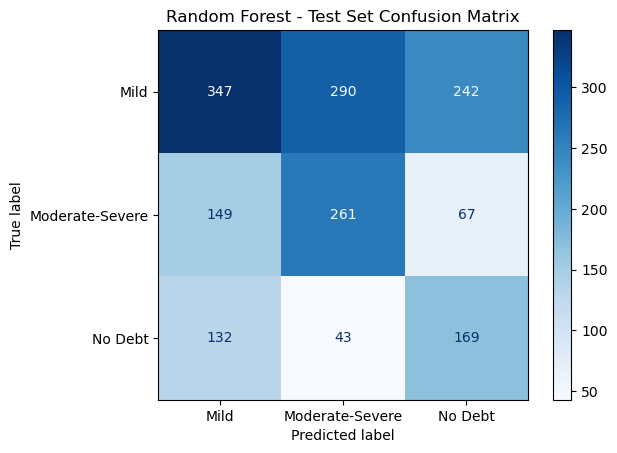

In [20]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)

rf_pipe = ImbPipeline([
    ('smote', SMOTE(random_state=random_state)),
    ('rf', RandomForestClassifier(random_state=random_state, n_jobs=-1))
])

param_dist = {
    'rf__n_estimators': [200, 400, 600],
    'rf__max_depth': [None, 5, 10, 20],
    'rf__min_samples_leaf': [1, 2, 5, 10],
    'rf__max_features': ['sqrt', 'log2', 0.5],
}

rf_search = RandomizedSearchCV(
    rf_pipe, param_dist, n_iter=20, scoring='f1_macro',
    cv=cv, random_state=random_state, n_jobs=-1, verbose=1
)
rf_search.fit(X_train_sel, y_train)   # SMOTE is applied to each training fold only

print("Best params:", rf_search.best_params_)
print(f"Best CV macro-F1: {rf_search.best_score_:.3f}")

best_rf = rf_search.best_estimator_
y_pred = best_rf.predict(X_test_sel)
print(classification_report(y_test, y_pred, target_names=encoder.classes_))
print(f"Test macro-F1: {f1_score(y_test, y_pred, average='macro'):.3f}")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=encoder.classes_, cmap='Blues')
plt.title("Random Forest - Test Set Confusion Matrix")
plt.show()

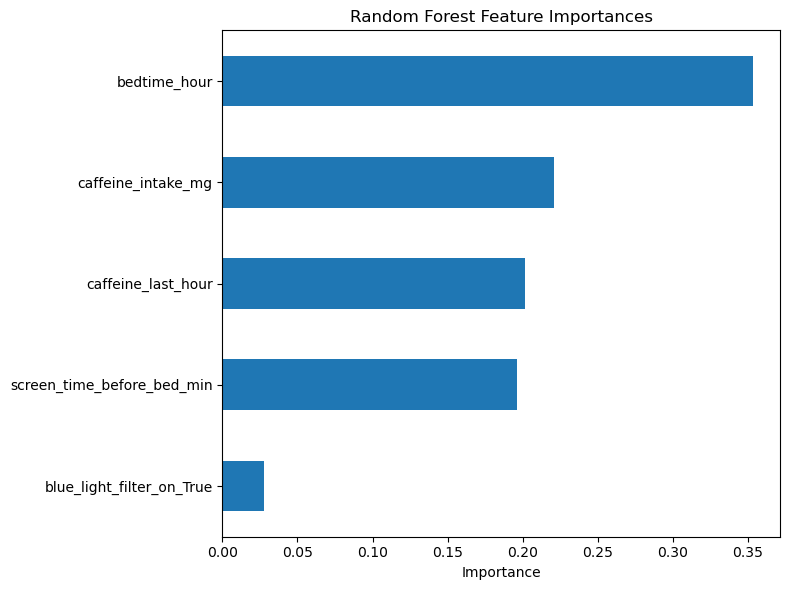

In [21]:
rf_model = best_rf.named_steps['rf']
importances = pd.Series(rf_model.feature_importances_, index=X_train_sel.columns).sort_values()

importances.plot(kind='barh', figsize=(8, 6))
plt.title("Random Forest Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

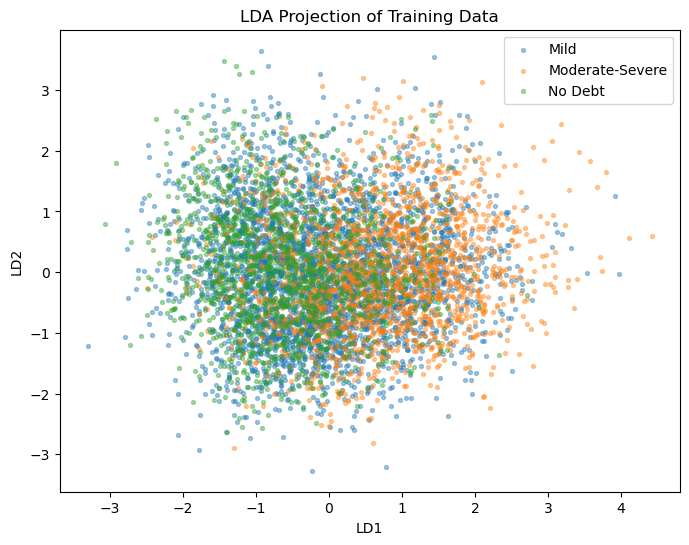

Explained variance ratio: [0.989 0.011]


In [22]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X_train, y_train)

plt.figure(figsize=(8, 6))
for label, name in enumerate(encoder.classes_):
    mask = y_train == label
    plt.scatter(X_lda[mask, 0], X_lda[mask, 1], s=8, alpha=0.4, label=name)
plt.xlabel("LD1"); plt.ylabel("LD2")
plt.title("LDA Projection of Training Data")
plt.legend()
plt.show()
print("Explained variance ratio:", lda.explained_variance_ratio_.round(3))